In [53]:
from datasets import Moffitt, DeCampos
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from inmoose.pycombat import pycombat_norm



In [2]:
moffit_adata = Moffitt.load_moffitt_ad()
decampos_adata = DeCampos.load_decampos_ad()

Moffitt Annotated data found!
DeCampos Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [5]:
common_genes = list(set(moffit_adata.to_df().columns) & set(decampos_adata.to_df().columns))
len(common_genes)

19194

In [9]:
moffit_expr = moffit_adata.to_df()[common_genes]
decampos_expr = decampos_adata.to_df()[common_genes]

In [32]:
moffit_expr["dataset"] = ["Moffitt" for i in range(len(moffit_expr.index))]
decampos_expr["dataset"] = ["DeCampos" for i in range(len(decampos_expr.index))]

In [33]:
merged_df = pd.concat([moffit_expr, decampos_expr])


In [43]:
merged_df["dataset"]

SL414065        Moffitt
SL316611        Moffitt
SL399348        Moffitt
SL242336        Moffitt
SL414057        Moffitt
                 ...   
SRR11586898    DeCampos
SRR11586901    DeCampos
SRR11586904    DeCampos
SRR11586905    DeCampos
SRR11586907    DeCampos
Name: dataset, Length: 149, dtype: str

In [35]:
merged_df_scaled = StandardScaler().fit_transform(merged_df.drop("dataset",axis=1))
embedding = PCA(n_components=2).fit_transform(merged_df_scaled)
embedding = pd.DataFrame(embedding, index=merged_df.index)
embedding["dataset"] = merged_df["dataset"]

In [36]:
embedding

,0,1,dataset
SL414065,73.674638,29.064354,Moffitt
SL316611,41.103231,-38.502917,Moffitt
SL399348,5.229003,-29.551129,Moffitt
SL242336,52.831102,16.990437,Moffitt
SL414057,45.018071,-13.809691,Moffitt
...,...,...,...
SRR11586898,-120.423426,12.385885,DeCampos
SRR11586901,-110.311113,77.174218,DeCampos
SRR11586904,-130.852024,15.141858,DeCampos
SRR11586905,-123.832405,61.698361,DeCampos


<Axes: xlabel='0', ylabel='1'>

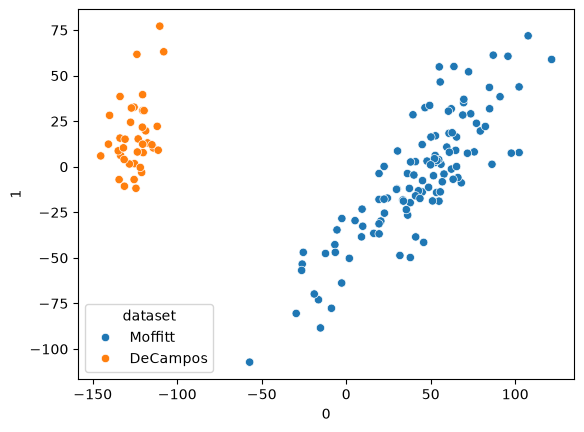

In [ ]:
sns.scatterplot(embedding,x=0,y=1,hue="dataset")

In [56]:
merged_df_harmonized = pycombat_norm(merged_df.transpose().drop("dataset",axis=0).astype(float), batch=merged_df["dataset"]).transpose()

/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-wl4ICAB4-py3.14/lib/python3.14/site-packages/inmoose/pycombat/pycombat_norm.py:125: RuntimeWarning: invalid value encountered in divide
  np.amax(np.absolute(g_new - np.asarray(g_old)) / np.asarray(g_old)),
/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-wl4ICAB4-py3.14/lib/python3.14/site-packages/inmoose/pycombat/pycombat_norm.py:126: RuntimeWarning: divide by zero encountered in divide
  np.amax(np.absolute(d_new - d_old) / d_old),


In [58]:
merged_df_harmonized["dataset"] = merged_df["dataset"]

In [59]:
merged_df_scaled = StandardScaler().fit_transform(merged_df_harmonized.drop("dataset",axis=1))
embedding = PCA(n_components=2).fit_transform(merged_df_scaled)
embedding = pd.DataFrame(embedding, index=merged_df.index)
embedding["dataset"] = merged_df["dataset"]

<Axes: xlabel='0', ylabel='1'>

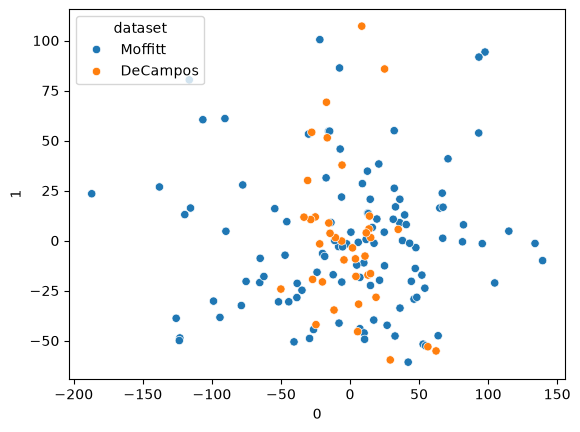

In [60]:
sns.scatterplot(embedding,x=0,y=1,hue="dataset")